<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%2021-30/Experiment%2022%3A%20Independent%20Component%20Analysis%20and%20Component%20Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

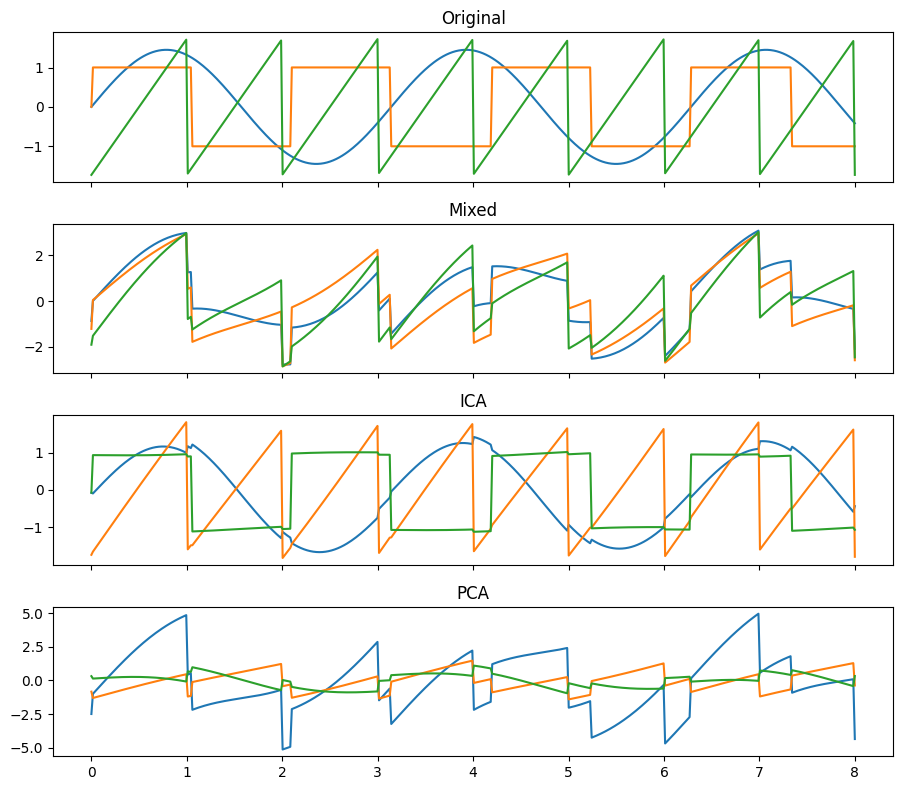

ICA Correlations: [np.float64(0.997), np.float64(0.999), np.float64(0.997)]
PCA Correlations: [np.float64(0.822), np.float64(0.722), np.float64(0.712)]


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.decomposition import FastICA, PCA

np.random.seed(42)

t = np.linspace(0, 8, 500)
S = np.c_[np.sin(2*t), np.sign(np.sin(3*t)), signal.sawtooth(2*np.pi*t)]
S /= S.std(axis=0)
X = S @ np.array([[1.0, 0.8, 0.5], [0.4, 1.2, 0.7], [0.6, 0.3, 1.1]]).T

S_ica = FastICA(n_components=3, random_state=42).fit_transform(X)
S_pca = PCA(n_components=3).fit_transform(X)

fig, axes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)
for ax, (name, d) in zip(axes, [("Original", S), ("Mixed", X), ("ICA", S_ica), ("PCA", S_pca)]):
    ax.plot(t, d)
    ax.set_title(name)
plt.tight_layout()
plt.show()

print("ICA Correlations:", [round(max(abs(np.corrcoef(S[:, i], S_ica[:, j])[0, 1]) for j in range(3)), 3) for i in range(3)])
print("PCA Correlations:", [round(max(abs(np.corrcoef(S[:, i], S_pca[:, j])[0, 1]) for j in range(3)), 3) for i in range(3)])